# Seeded Weekly Comparison — DQN vs DQN No-LLM vs Buy & Hold

**Test period:** 2024-01-05 → 2026-02-02  |  Weekly rebalancing  |  10% stop-loss  |  5 seeds  |  $10,000 starting capital


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

summary_path = 'test_results/seeded_weekly_full/seeded_weekly_summary.csv'
raw_path     = 'test_results/seeded_weekly_full/seeded_weekly_runs.csv'
summary = pd.read_csv(summary_path)
raw     = pd.read_csv(raw_path)

TICKERS    = sorted(summary['ticker'].unique())
START_DATE = '2024-01-01'

# ── Buy & Hold: first/last adjusted_close on or after START_DATE ─────────────
bah = {}
for t in TICKERS:
    path = f'data/{t}_weekly_stock_data.csv'
    if not os.path.exists(path):
        bah[t] = dict(ret=np.nan, start_date='N/A', end_date='N/A', start_price=np.nan, end_price=np.nan)
        continue
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    df = df[df.index >= START_DATE].sort_index().dropna(subset=['adjusted_close'])
    p0, p1 = df['adjusted_close'].iloc[0], df['adjusted_close'].iloc[-1]
    bah[t] = dict(
        ret=round((p1/p0 - 1)*100, 2),
        start_date=str(df.index[0].date()),
        end_date=str(df.index[-1].date()),
        start_price=round(p0, 2),
        end_price=round(p1, 2),
    )

bah_df = pd.DataFrame(bah).T.reset_index().rename(columns={'index': 'ticker'})
print(f"Test window: {bah_df['start_date'].iloc[0]}  →  {bah_df['end_date'].iloc[0]}")
bah_df[['ticker','start_date','end_date','start_price','end_price','ret']].rename(columns={'ret':'bah_return_pct'}).round(2)


Test window: 2024-01-05  →  2026-02-02


,ticker,start_date,end_date,start_price,end_price,bah_return_pct
0,AAPL,2024-01-05,2026-02-02,179.5,270.01,50.42
1,AMZN,2024-01-05,2026-02-02,145.24,242.96,67.28
2,ASML,2024-01-05,2026-02-02,688.27,1441.39,109.42
3,GOOGL,2024-01-05,2026-02-02,134.7,343.69,155.14
4,META,2024-01-05,2026-02-02,349.53,706.41,102.1
5,MSFT,2024-01-05,2026-02-02,362.36,423.37,16.84
6,NVDA,2024-01-05,2026-02-02,49.07,185.61,278.26
7,TSLA,2024-01-05,2026-02-02,237.49,421.81,77.61
8,TSM,2024-01-05,2026-02-02,96.94,341.36,252.14


In [3]:
def fmt(mean, std, d=1):
    return f"{mean:.{d}f} ± {std:.{d}f}"

def best(dqn_val, nollm_val, bah_val=None, lower_is_better=False):
    vals = {'DQN': dqn_val, 'No-LLM': nollm_val}
    if bah_val is not None:
        vals['B&H'] = bah_val
    winner = (min if lower_is_better else max)(vals, key=vals.get)
    return {'DQN': '🟦', 'No-LLM': '⬜', 'B&H': '🟨'}[winner]

s = summary.set_index(['ticker', 'method'])

rows = []
for t in TICKERS:
    d  = s.loc[(t, 'dqn')]
    nl = s.loc[(t, 'dqn_nollm')]
    bh = float(bah_df.set_index('ticker').loc[t, 'ret'])
    rows.append({
        'Ticker':            t,
        'B&H Return %':      f"{bh:.1f}%",
        'DQN Return %':      fmt(d['return_mean_pct'],  d['return_std_pct'])  + '%',
        'No-LLM Return %':   fmt(nl['return_mean_pct'], nl['return_std_pct']) + '%',
        '★ Return':          best(d['return_mean_pct'],  nl['return_mean_pct'], bh),
        'DQN Sharpe':        fmt(d['sharpe_mean'],  d['sharpe_std'], 2),
        'No-LLM Sharpe':     fmt(nl['sharpe_mean'], nl['sharpe_std'], 2),
        '★ Sharpe':          best(d['sharpe_mean'], nl['sharpe_mean']),
        'DQN MaxDD %':       fmt(d['max_drawdown_mean'],  d['max_drawdown_std']),
        'No-LLM MaxDD %':    fmt(nl['max_drawdown_mean'], nl['max_drawdown_std']),
        '★ MaxDD':           best(d['max_drawdown_mean'], nl['max_drawdown_mean'], lower_is_better=True),
        'DQN Win Rate %':    fmt(d['win_rate_mean'],  d['win_rate_std']),
        'No-LLM Win Rate %': fmt(nl['win_rate_mean'], nl['win_rate_std']),
        '★ Win Rate':        best(d['win_rate_mean'], nl['win_rate_mean']),
    })

display(pd.DataFrame(rows).set_index('Ticker'))
print('\n🟦 DQN (LLM)   ⬜ No-LLM   🟨 Buy & Hold')


,B&H Return %,DQN Return %,No-LLM Return %,★ Return,DQN Sharpe,No-LLM Sharpe,★ Sharpe,DQN MaxDD %,No-LLM MaxDD %,★ MaxDD,DQN Win Rate %,No-LLM Win Rate %,★ Win Rate
Ticker,,,,,,,,,,,,,
AAPL,50.4%,26.7 ± 25.1%,31.7 ± 14.7%,🟨,1.15 ± 0.90,1.48 ± 0.39,⬜,26.5 ± 3.7,25.4 ± 11.7,⬜,33.6 ± 8.7,37.5 ± 19.0,⬜
AMZN,67.3%,43.4 ± 27.1%,30.8 ± 17.6%,🟨,1.90 ± 1.02,1.23 ± 0.69,🟦,21.1 ± 9.5,20.7 ± 11.8,⬜,30.7 ± 9.7,35.3 ± 19.9,⬜
ASML,109.4%,39.2 ± 12.9%,44.4 ± 36.2%,🟨,1.45 ± 0.28,1.60 ± 0.63,⬜,27.6 ± 8.1,27.9 ± 16.5,🟦,34.2 ± 7.0,35.5 ± 19.9,⬜
GOOGL,155.1%,51.2 ± 38.2%,98.6 ± 55.9%,🟨,2.11 ± 1.12,2.68 ± 1.51,⬜,23.8 ± 9.0,22.9 ± 13.6,⬜,27.3 ± 6.0,43.5 ± 24.3,⬜
META,102.1%,45.1 ± 18.6%,14.1 ± 26.1%,🟨,1.71 ± 0.49,0.41 ± 1.56,🟦,33.5 ± 1.1,32.6 ± 1.7,⬜,39.6 ± 6.5,42.2 ± 19.3,⬜
MSFT,16.8%,-6.0 ± 9.6%,-3.2 ± 2.6%,🟨,-0.14 ± 0.54,-0.08 ± 0.49,⬜,20.7 ± 3.0,23.6 ± 8.2,🟦,37.3 ± 5.6,43.3 ± 23.7,⬜
NVDA,278.3%,111.0 ± 62.2%,90.8 ± 68.8%,🟨,2.49 ± 0.98,2.06 ± 1.44,🟦,27.1 ± 7.7,25.1 ± 11.2,⬜,32.0 ± 5.0,32.2 ± 18.0,⬜
TSLA,77.6%,66.8 ± 63.4%,32.1 ± 48.9%,🟨,1.52 ± 1.05,0.53 ± 1.55,🟦,33.3 ± 6.2,38.9 ± 8.5,🟦,15.5 ± 4.8,22.5 ± 12.2,⬜
TSM,252.1%,52.4 ± 24.3%,94.6 ± 66.4%,🟨,2.13 ± 0.81,2.04 ± 2.05,🟦,25.6 ± 6.9,27.0 ± 10.2,🟦,26.7 ± 5.9,40.2 ± 23.1,⬜



🟦 DQN (LLM)   ⬜ No-LLM   🟨 Buy & Hold


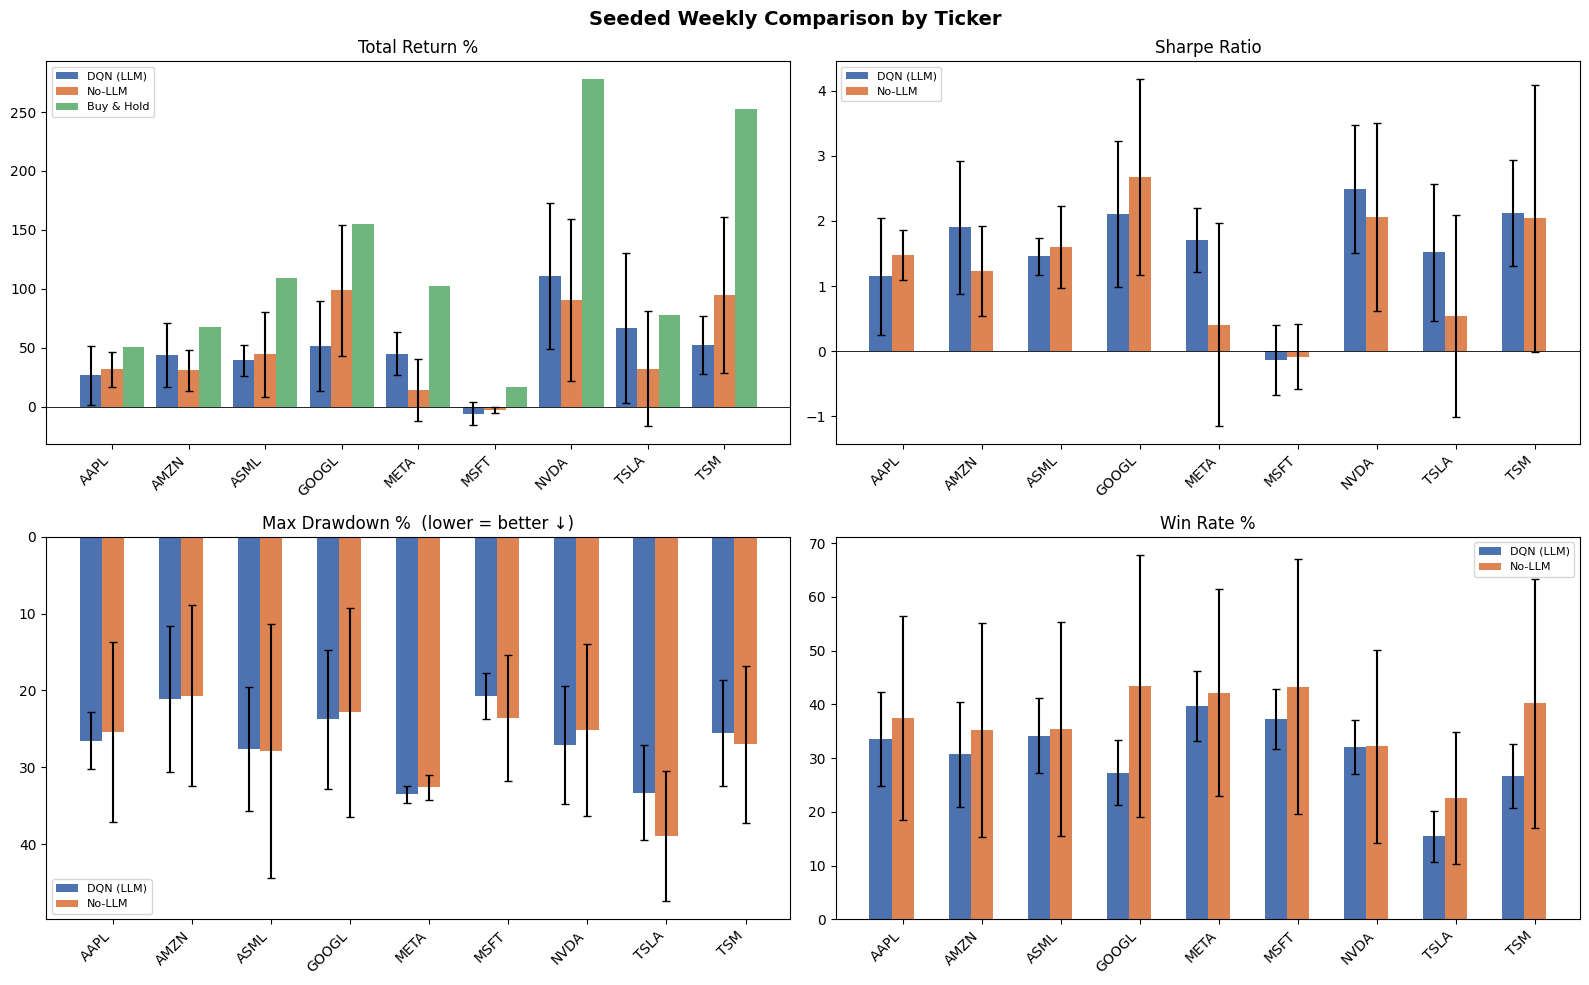

In [4]:
dqn   = summary[summary['method']=='dqn'].set_index('ticker').loc[TICKERS]
nollm = summary[summary['method']=='dqn_nollm'].set_index('ticker').loc[TICKERS]
bah_ret = [float(bah_df.set_index('ticker').loc[t, 'ret']) for t in TICKERS]

x = np.arange(len(TICKERS))
w = 0.28
c_dqn, c_nollm, c_bah = '#4C72B0', '#DD8452', '#55A868'

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Seeded Weekly Comparison by Ticker', fontsize=14, fontweight='bold')

panels = [
    ('Total Return %',   'return_mean_pct',    'return_std_pct',    False),
    ('Sharpe Ratio',     'sharpe_mean',         'sharpe_std',        False),
    ('Max Drawdown %',   'max_drawdown_mean',   'max_drawdown_std',  True),
    ('Win Rate %',       'win_rate_mean',       'win_rate_std',      False),
]

for ax, (title, col, std_col, invert) in zip(axes.flat, panels):
    ax.bar(x - w,   dqn[col],   w, yerr=dqn[std_col],   capsize=3, label='DQN (LLM)', color=c_dqn)
    ax.bar(x,       nollm[col], w, yerr=nollm[std_col], capsize=3, label='No-LLM',    color=c_nollm)
    if title in ('Total Return %',):
        ax.bar(x + w, bah_ret, w, label='Buy & Hold', color=c_bah, alpha=0.85)
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(TICKERS, rotation=45, ha='right')
    ax.axhline(0, color='black', linewidth=0.6)
    ax.legend(fontsize=8)
    if invert:
        ax.invert_yaxis()
        ax.set_title(title + '  (lower = better ↓)')

plt.tight_layout()
plt.show()


In [5]:
print("=== Score Card ===\n")

dqn_wins_ret  = sum(dqn.loc[t,'return_mean_pct']  > nollm.loc[t,'return_mean_pct']  for t in TICKERS)
dqn_wins_sr   = sum(dqn.loc[t,'sharpe_mean']       > nollm.loc[t,'sharpe_mean']       for t in TICKERS)
dqn_wins_wr   = sum(dqn.loc[t,'win_rate_mean']     > nollm.loc[t,'win_rate_mean']     for t in TICKERS)
dqn_wins_dd   = sum(dqn.loc[t,'max_drawdown_mean'] < nollm.loc[t,'max_drawdown_mean'] for t in TICKERS)

n = len(TICKERS)
print(f"DQN (LLM) beats No-LLM  →  Return: {dqn_wins_ret}/{n}  |  Sharpe: {dqn_wins_sr}/{n}  |  Win Rate: {dqn_wins_wr}/{n}  |  Lower MaxDD: {dqn_wins_dd}/{n}")

dqn_bah_beat  = sum(dqn.loc[t,'return_mean_pct']   > float(bah_df.set_index('ticker').loc[t,'ret']) for t in TICKERS)
nollm_bah_beat= sum(nollm.loc[t,'return_mean_pct'] > float(bah_df.set_index('ticker').loc[t,'ret']) for t in TICKERS)
print(f"Beats Buy & Hold         →  DQN: {dqn_bah_beat}/{n}  |  No-LLM: {nollm_bah_beat}/{n}")

print(f"\nAverages across all tickers:")
print(f"  Sharpe    — DQN: {dqn['sharpe_mean'].mean():.2f}  |  No-LLM: {nollm['sharpe_mean'].mean():.2f}")
print(f"  MaxDD %   — DQN: {dqn['max_drawdown_mean'].mean():.1f}  |  No-LLM: {nollm['max_drawdown_mean'].mean():.1f}")
print(f"  Win Rate% — DQN: {dqn['win_rate_mean'].mean():.1f}  |  No-LLM: {nollm['win_rate_mean'].mean():.1f}")

=== Score Card ===

DQN (LLM) beats No-LLM  →  Return: 4/9  |  Sharpe: 5/9  |  Win Rate: 0/9  |  Lower MaxDD: 4/9
Beats Buy & Hold         →  DQN: 0/9  |  No-LLM: 0/9

Averages across all tickers:
  Sharpe    — DQN: 1.59  |  No-LLM: 1.33
  MaxDD %   — DQN: 26.6  |  No-LLM: 27.1
  Win Rate% — DQN: 30.8  |  No-LLM: 36.9


In [6]:
pivot = raw.groupby(['ticker','method'])['total_return_pct'].max().unstack()
pivot.columns = ['DQN (LLM) max%', 'No-LLM max%']
pivot['Winner'] = pivot.apply(lambda r: '🟦 DQN' if r['DQN (LLM) max%'] > r['No-LLM max%'] else '⬜ No-LLM', axis=1)
pivot['Gap'] = (pivot['DQN (LLM) max%'] - pivot['No-LLM max%']).round(1).apply(lambda v: f"+{v}" if v > 0 else str(v))
display(pivot.round(1))

,DQN (LLM) max%,No-LLM max%,Winner,Gap
ticker,,,,
AAPL,58.6,48.6,🟦 DQN,+9.9
AMZN,61.7,44.3,🟦 DQN,+17.5
ASML,54.4,79.7,⬜ No-LLM,-25.3
GOOGL,108.4,137.9,⬜ No-LLM,-29.5
META,76.8,35.2,🟦 DQN,+41.7
MSFT,7.5,-0.1,🟦 DQN,+7.6
NVDA,171.2,165.7,🟦 DQN,+5.5
TSLA,139.6,84.9,🟦 DQN,+54.7
TSM,89.4,157.6,⬜ No-LLM,-68.1
